# 1_gridsearch: extreme facular geometries at v_eq = 4000 m/s, 430-440 nm

Forward-models polar caps, an equatorial band and bands at +/-30 deg, each tuned to a visible-disk filling factor of 10, 20 and 50% at i = 0, 45 and 90 deg (res3d = 5, res2d = 200), then generates a disk with randomly placed faculae and finds the grid spectrum with the lowest chi^2 against it.

Photosphere: real SSD (with lines). Facula: 200G. Run from `actress_highres/actress/` (all paths are relative to it).

In [2]:
import os
import sys
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import actress.contrasts as contrst

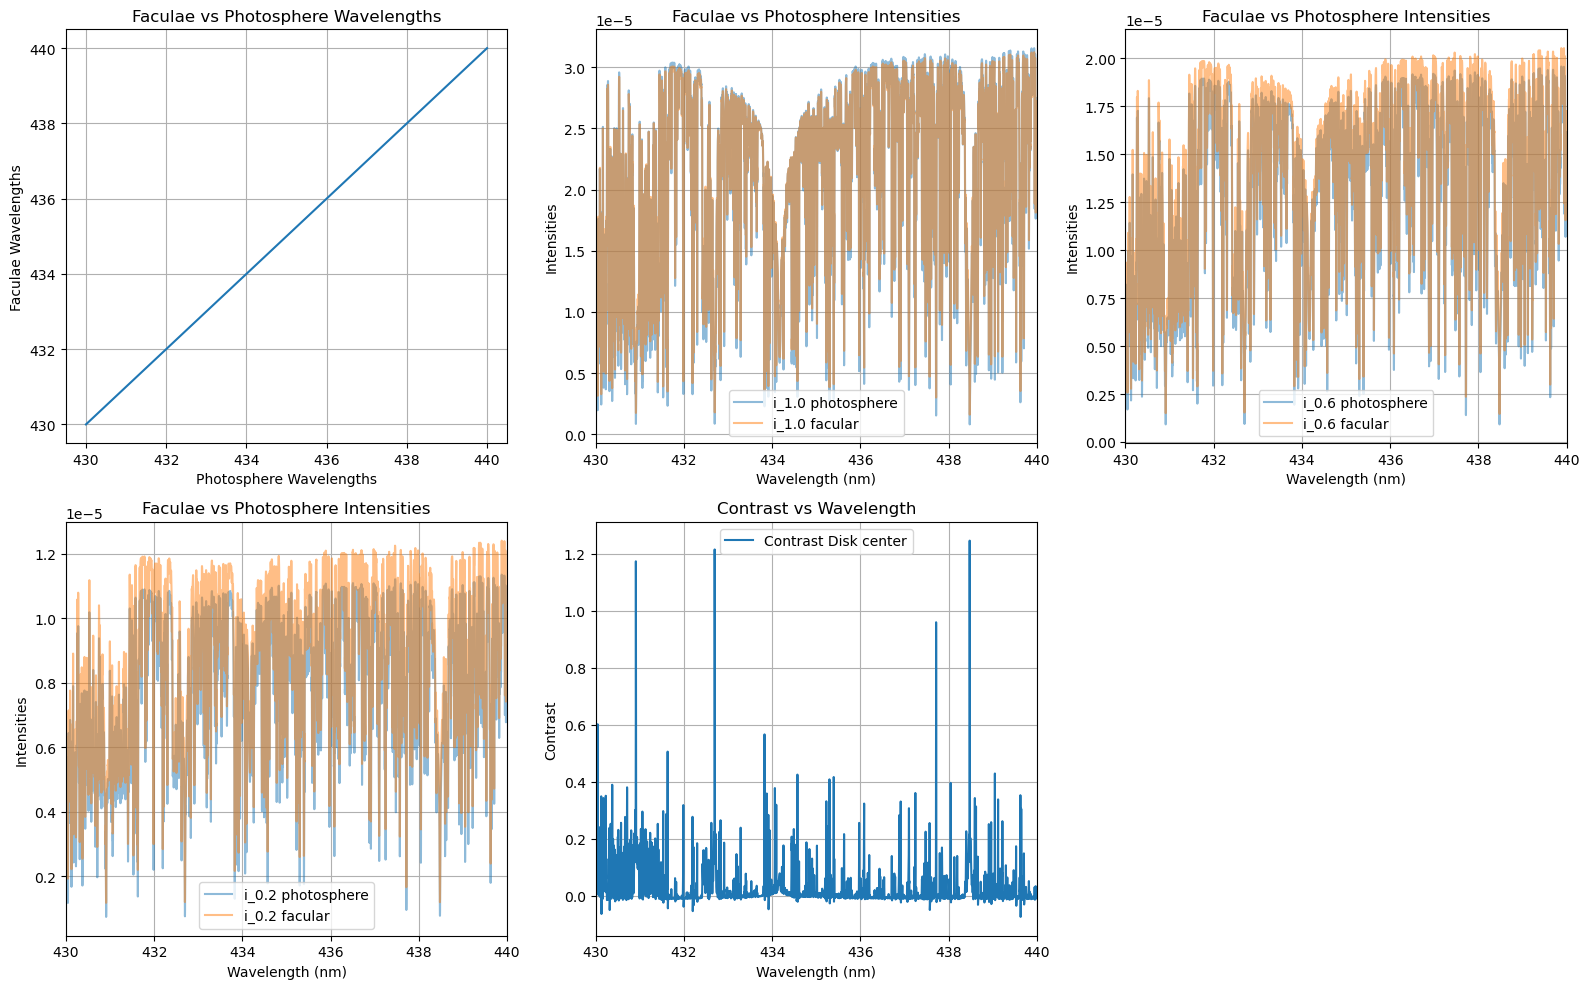

Saved to test_fac_200G_4300_4400.txt
Saved to test_phot_ssd_4300_4400.txt


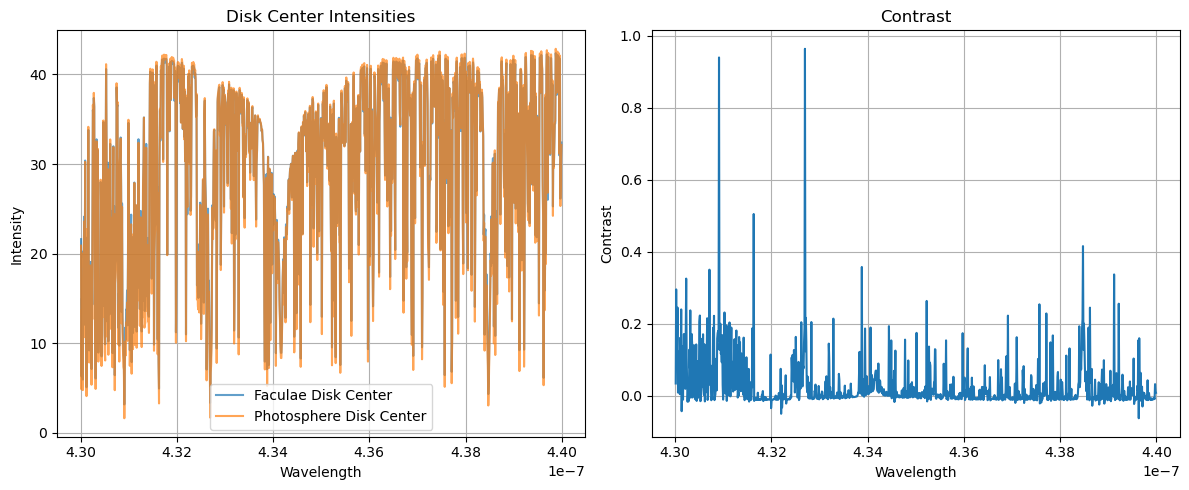

The effective temperature is 1947.1344512200421 K


In [ ]:
import actress.contrasts as contrst
import numpy as np

fac_file = './inputs/limb_files/average_intensities_200G_driftcorrected.txt'
phot_file = './inputs/limb_files/average_intensities_ssd_driftcorrected.txt'
ld_law = 'power2'
N = 1000


#Jean line 1 broad region
# wav_lower = 4.3767e-7
# wav_higher = 4.3777e-7

#Jean line 1
# wav_lower=4.3759e-7
# wav_higher=4.3761e-7

#Jean's 2nd line
# wav_lower=4.37935e-7
# wav_higher=4.37965e-7

#Jean flat region
# wav_lower = 4.3760e-7
# wav_higher = 4.37680e-7

#Jean blue of line 1
# wav_lower = 4.3747e-7
# wav_higher =  4.3757e-7

#True Jean line 1
# wav_lower = 4.3765e-7
# wav_higher = 4.3775e-7

#True Jean line 2
# wav_lower = 4.3835e-7
# wav_higher = 4.386e-7

#True Jean line 2
# wav_lower = 4.366e-7
# wav_higher = 4.371e-7

#Jean whole range
wav_lower = 4.300e-7
wav_higher = 4.400e-7


#Kroll line 1
# wav_lower = 4.49255e-7
# wav_higher = 4.49275e-7

contrst.validate_inputs(fac_file, phot_file, wav_lower, wav_higher, graphs = True)

contrst.contrast(fac_file, wav_lower=wav_lower, wav_higher=wav_higher, N=N, ld_law=ld_law, save='test_fac_200G_4300_4400_new.txt', graphs=False)
contrst.contrast(phot_file, wav_lower=wav_lower, wav_higher=wav_higher, N=N, ld_law=ld_law, save='test_phot_ssd_4300_4400_new.txt', graphs=False)

contrst.validate_outputs('test_fac_200G_4300_4400_new.txt', 'test_phot_ssd_4300_4400_new.txt', graphs = True)
contrst.teff(fac_file)

Saved to test_phot_ssd_4300_4400_new.txt
Wrote test_phot_ssd_4300_4400_new.txt (8 s)
Saved to test_fac_200G_4300_4400_new.txt
Wrote test_fac_200G_4300_4400_new.txt (5 s)
11473 wavelengths, 4300.0980-4399.8999 A; images at 4384.7640 A (I0_fac / I0_phot = 2.245)

run                          half-width (deg) target ff visible ff  strips (lower, upper) deg
polar_caps_ff0.10_i0                   19.093      0.10     0.0988  (-90.00, -70.91), (70.91, 90.00)
polar_caps_ff0.20_i0                   26.552      0.20     0.1894  (-90.00, -63.45), (63.45, 90.00)
polar_caps_ff0.50_i0                   45.006      0.50     0.4870  (-90.00, -44.99), (44.99, 90.00)
polar_caps_ff0.10_i45                  22.065      0.10     0.0938  (-90.00, -67.93), (67.93, 90.00)
polar_caps_ff0.20_i45                  32.600      0.20     0.1973  (-90.00, -57.40), (57.40, 90.00)
polar_caps_ff0.50_i45                  55.771      0.50     0.5010  (-90.00, -34.23), (34.23, 90.00)
polar_caps_ff0.10_i90                 

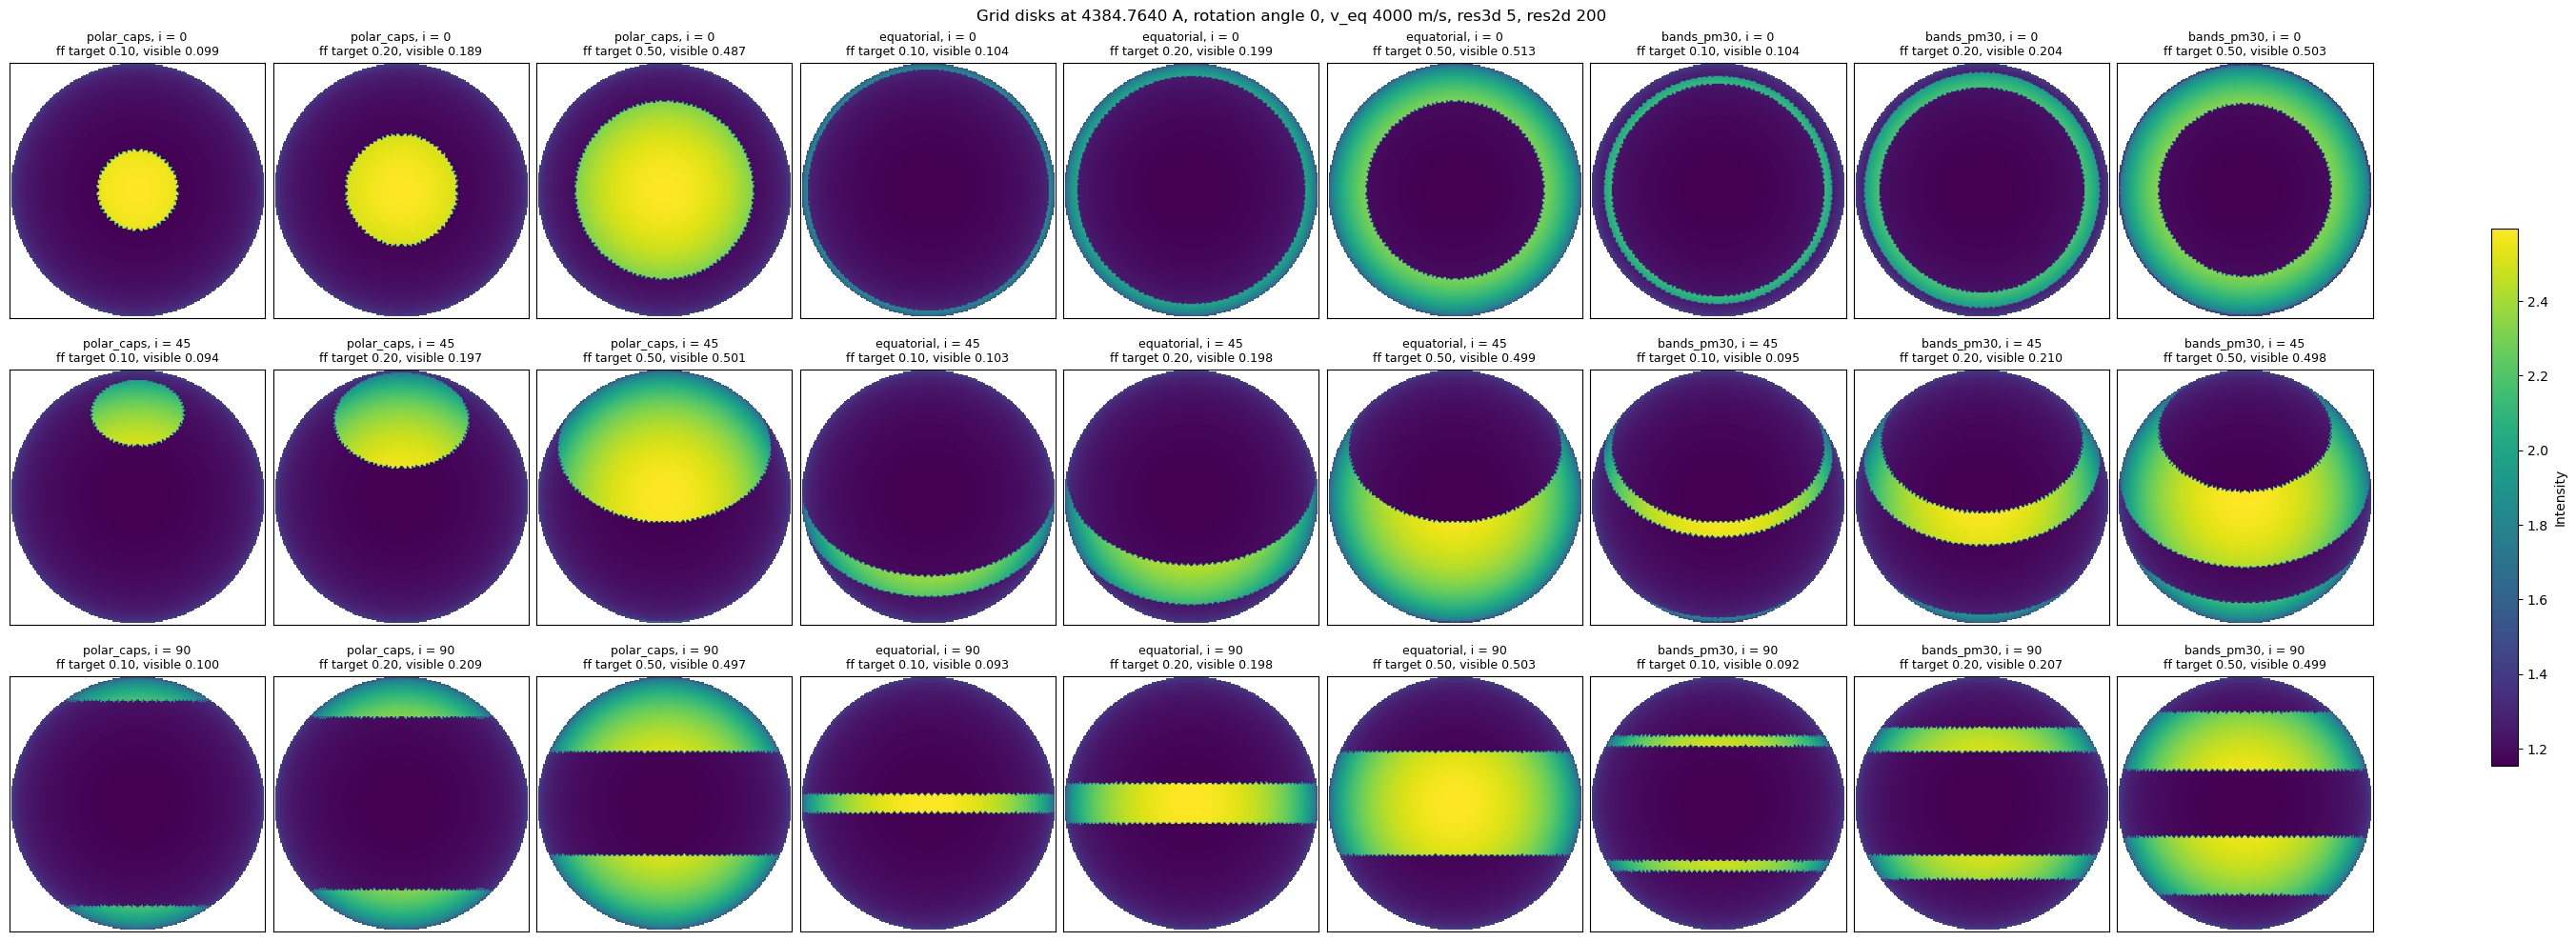

Random disk: 112 faculae, r = 5 deg, i = 45, visible ff 0.1993, seed 0
chi^2 over 11457 bins, 4300.1668-4399.8295 A, spectra normalised to their mean
rank run                          visible ff        chi^2
   1 bands_pm30_ff0.20_i45            0.2096  1.91149e-03
   2 polar_caps_ff0.20_i45            0.1973  5.72530e-03
   3 equatorial_ff0.20_i45            0.1976  1.40922e-02
   4 polar_caps_ff0.10_i45            0.0938  7.07748e-02
   5 bands_pm30_ff0.10_i45            0.0951  7.49102e-02
   6 equatorial_ff0.10_i45            0.1029  8.65670e-02
   7 equatorial_ff0.50_i45            0.4990  3.94001e-01
   8 bands_pm30_ff0.50_i45            0.4982  5.10696e-01
   9 polar_caps_ff0.50_i45            0.5010  6.67022e-01
  10 polar_caps_ff0.10_i90            0.0999  3.82629e+00
  11 polar_caps_ff0.20_i90            0.2086  3.93269e+00
  12 bands_pm30_ff0.10_i90            0.0918  4.07660e+00
  13 equatorial_ff0.10_i90            0.0928  4.17713e+00
  14 bands_pm30_ff0.20_i90            

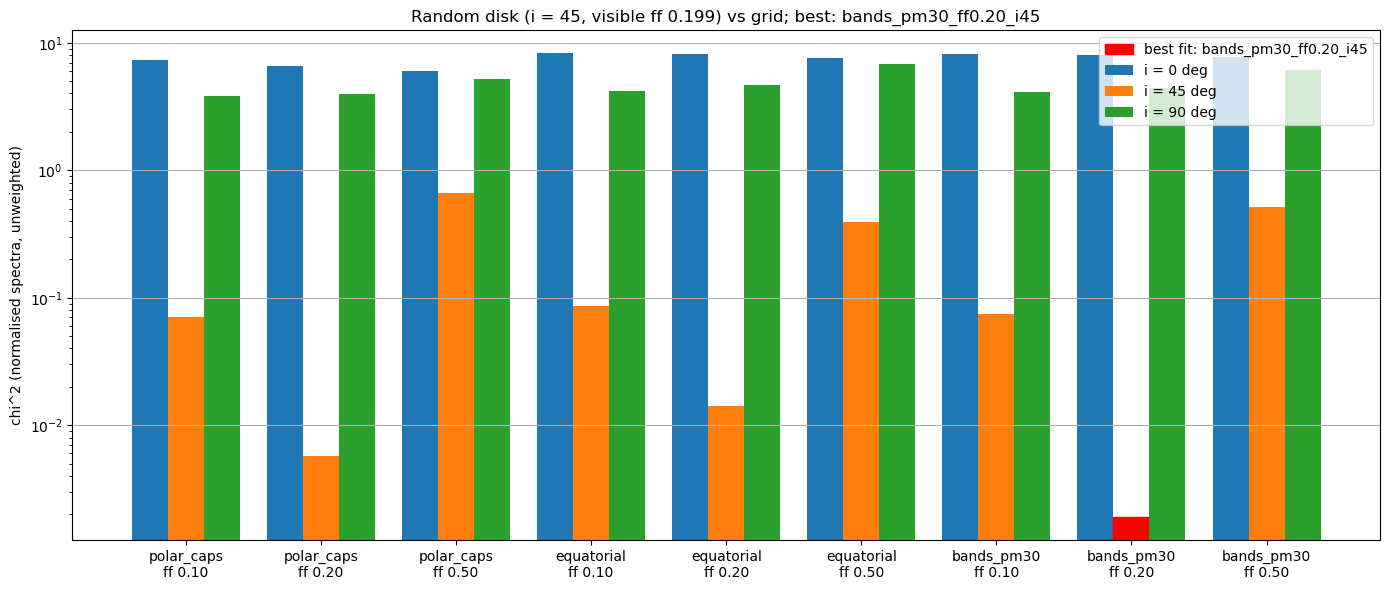

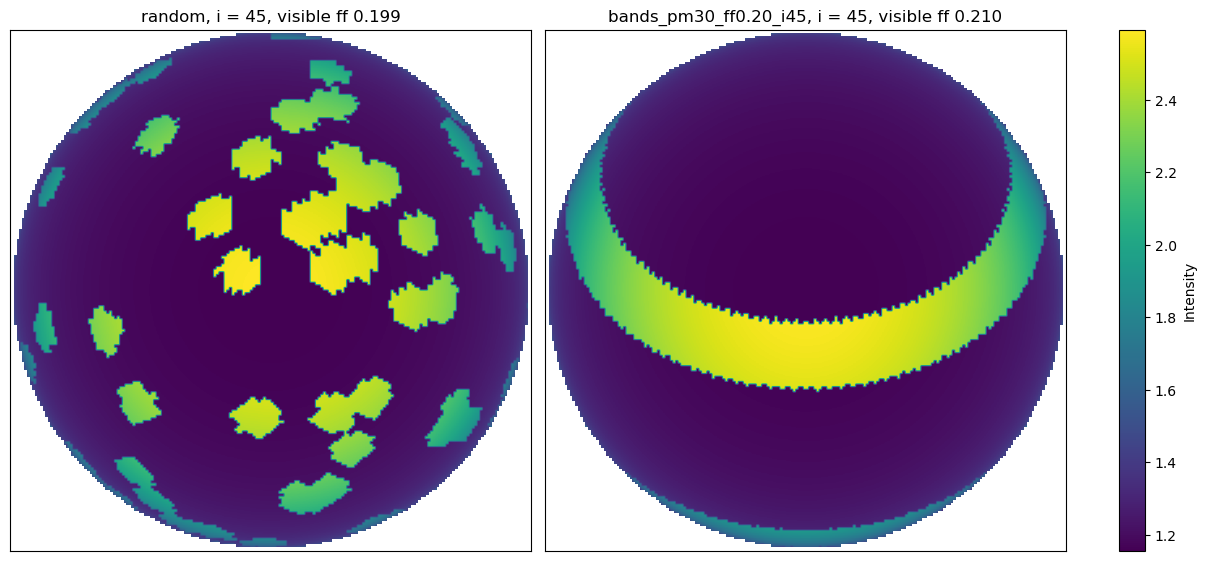

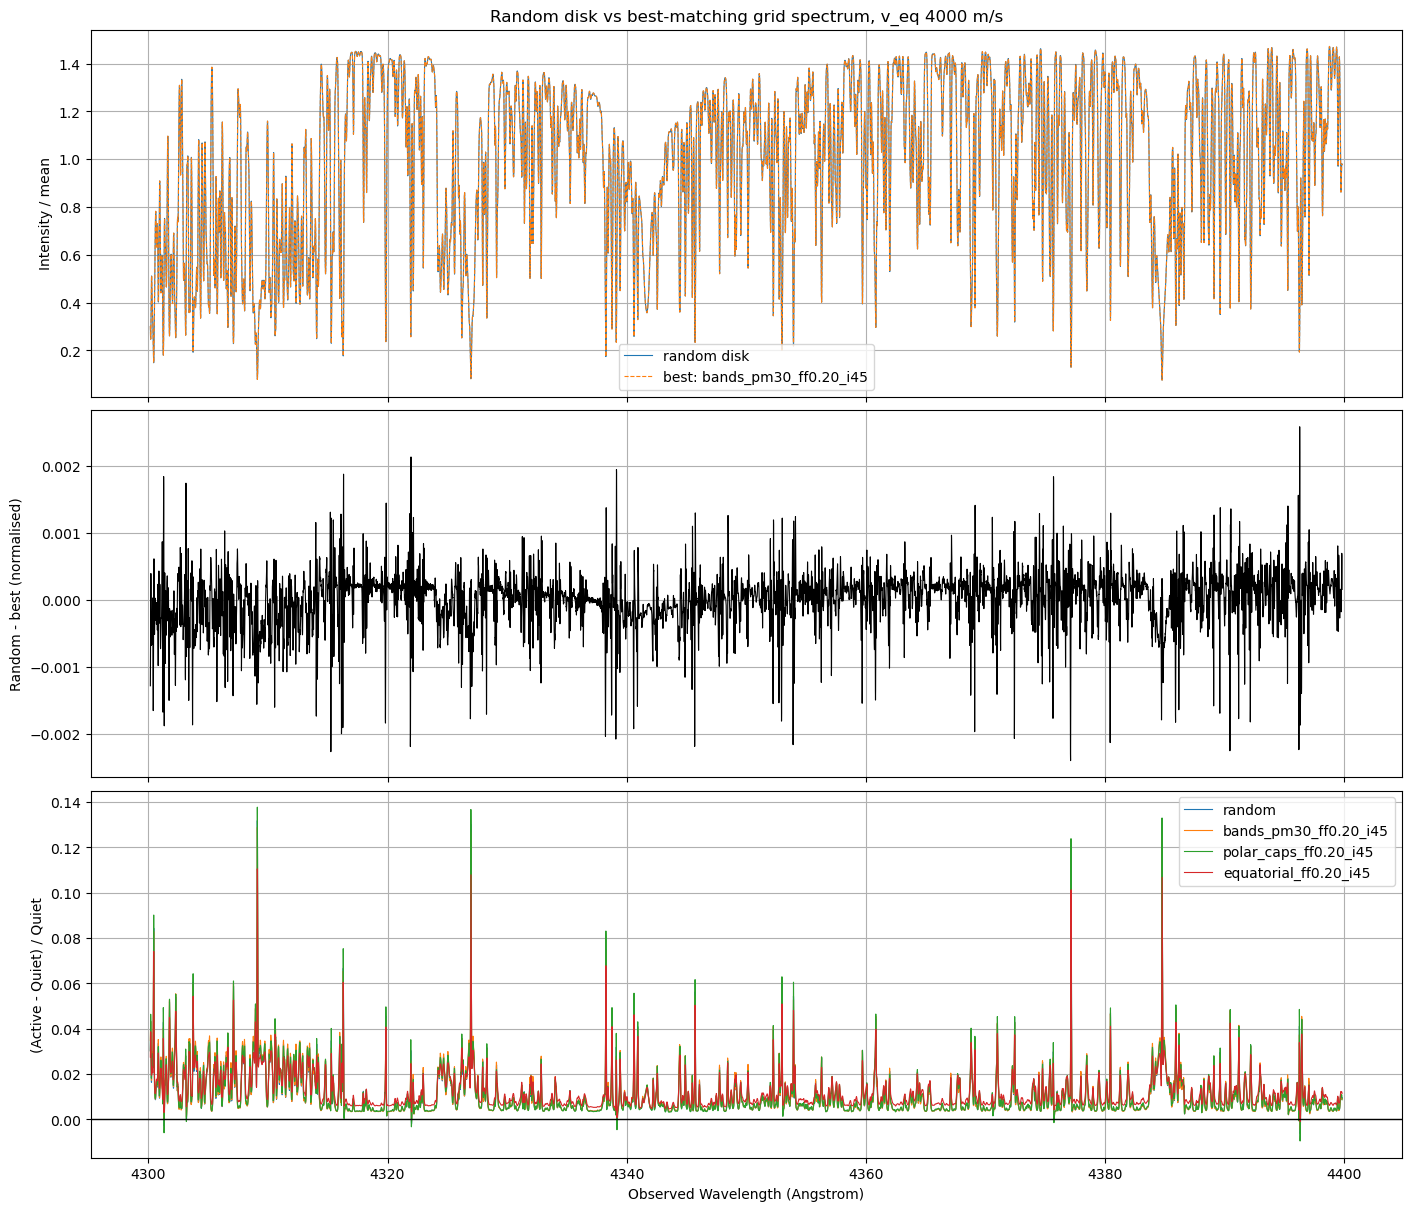

In [3]:
# ===== 1_gridsearch: extreme facular geometries at v_eq = 4000 m/s, 430-440 nm =====
# Forward-models a grid of axisymmetric facular geometries (polar caps, equatorial band,
# bands at +/-30 deg), each tuned to a target VISIBLE-disk filling factor at i = 0, 45, 90,
# then makes a disk with randomly placed faculae and finds the grid spectrum with the lowest
# chi^2 against it.
#
# Photosphere: the real SSD (with lines), NOT the continuum SSD used above. The continuum file
# is one flat level per mu from the 437.0-438.4 nm maximum, ~5x the SSD intensity near 430 nm,
# so it is not a quiet star over the whole range.
#
# Disks are not written per wavelength: disk_save would be ~11,500 files x 320 kB per run
# (>100 GB for the grid on /rds). Each disk is Doppler-shifted and binned into the spectrum as
# it is made, with exactly the steps of disk_utils.process_disk_directory (checked against
# sim_spectrum(disk_save=...) + process_disk_directory on the 4376 A window: identical bins,
# max relative difference 2e-14, i.e. summation order). Only the spectra and one image per run
# are cached, to a new file that is never overwritten.
import time
import actress as ac
import actress.run_actress_notebook as actr

grid_phot_file = './inputs/limb_files/average_intensities_ssd_driftcorrected.txt'   # real SSD, with lines
grid_fac_file = './inputs/limb_files/average_intensities_200G_driftcorrected.txt'
grid_phot_ld_file = 'test_phot_ssd_4300_4400_new.txt'
grid_fac_ld_file = 'test_fac_200G_4300_4400_new.txt'
grid_ld_law = 'power2'
# The files span 430.00034-440.00055 nm. contrast() takes delta_freq from both neighbours of
# each kept sample, so the two end samples cannot be used; start and stop one sample inside.
grid_wav_lower = 4.3001e-7   # m
grid_wav_higher = 4.3999e-7  # m

grid_v_eq = 4000                  # m/s, equatorial rotation velocity, fixed for every run
grid_incs = [0, 45, 90]           # deg, i = 90 is equator-on; at i = 0 the strip pole lat = +90 faces us
grid_target_ffs = [0.10, 0.20, 0.50]   # visible-disk filling factor, sim.getdiscfill at rotation angle 0
grid_geometries = ['polar_caps', 'equatorial', 'bands_pm30']
grid_res3d = 5                    # healpix nside = 2^5
grid_res2d = 200                  # pixels across the projected disk
# At nside 32 the visible ff moves in steps of up to ~0.026 (one healpix ring), so the target
# can only be hit to about half a step. Anything further off means the solver failed.
grid_ff_tolerance = 0.02
grid_n_workers = 8                # processes; this runs on a shared login node

# Random-faculae test disk: circular faculae uniform on the sphere, added one at a time until
# the visible ff reaches the target, keeping whichever count lands closer to it.
grid_random_inc = 45              # deg
grid_random_r = 5                 # deg, facula radius
grid_random_seed = 0
grid_random_target_ff = 0.20

grid_cache_file = (f'./outputs/gridsearch/1_gridsearch_v{grid_v_eq}_res3d{grid_res3d}_res2d{grid_res2d}'
                   f'_{grid_wav_lower * 1e10:.1f}_{grid_wav_higher * 1e10:.1f}_randomseed{grid_random_seed}.npz')

# ----- limb-darkening fits over 430-440 nm, every native sample -----
grid_file_wav_nm = pd.read_csv(grid_phot_file, sep=r'\s+', comment='#').values[:, 0]   # nm
grid_log_grid_wav = contrst.wav_nm_to_m(contrst.log_uniform_grid(grid_file_wav_nm, R=500000))   # m, the grid contrast() uses
grid_indx_low, grid_indx_high = contrst.wav_limits(list(grid_log_grid_wav), grid_wav_lower, grid_wav_higher)
if grid_indx_low < 1 or grid_indx_high > len(grid_log_grid_wav) - 2:
    raise ValueError(f"Window indices {grid_indx_low}-{grid_indx_high} leave no neighbour for delta_freq")
# N such that contrast()'s step round((high - low) / N) is 1: every 0.0087 A (~600 m/s) sample is
# kept, rather than every 2nd as in the 4376 cells, so the 4000 m/s broadening spans ~13 bins.
grid_N_ld = grid_indx_high - grid_indx_low

contrst.validate_inputs(grid_fac_file, grid_phot_file, grid_wav_lower, grid_wav_higher, graphs=False)
for source_file, ld_file in ((grid_phot_file, grid_phot_ld_file), (grid_fac_file, grid_fac_ld_file)):
    if os.path.exists(ld_file):
        print(f"Using existing {ld_file}")
        continue
    t_start = time.time()
    contrst.contrast(source_file, wav_lower=grid_wav_lower, wav_higher=grid_wav_higher, N=grid_N_ld,
                     ld_law=grid_ld_law, save=ld_file, graphs=False)
    print(f"Wrote {ld_file} ({time.time() - t_start:.0f} s)")
contrst.validate_outputs(grid_fac_ld_file, grid_phot_ld_file, graphs=False)

grid_phot_ld = np.loadtxt(grid_phot_ld_file)   # columns: wavelength (m), I0, c1, c2
grid_fac_ld = np.loadtxt(grid_fac_ld_file)
if len(grid_phot_ld) != grid_indx_high - grid_indx_low + 1:
    raise ValueError(f"{grid_phot_ld_file} has {len(grid_phot_ld)} rows, expected every sample "
                     f"{grid_indx_low}-{grid_indx_high}; it was made with different settings")

# Wavelength labels exactly as run_actress_notebook formats them, and the bins
# process_disk_directory builds from them: centres are the sampled wavelengths themselves.
grid_wavelength_texts = [f"{wav * 1e10:.4f}" for wav in grid_phot_ld[:, 0]]
grid_input_wavelengths = np.array([float(text) for text in grid_wavelength_texts])   # Angstrom
grid_midpoints = 0.5 * (grid_input_wavelengths[:-1] + grid_input_wavelengths[1:])
grid_bin_edges = np.concatenate((
    [grid_input_wavelengths[0] - (grid_input_wavelengths[1] - grid_input_wavelengths[0]) / 2],
    grid_midpoints,
    [grid_input_wavelengths[-1] + (grid_input_wavelengths[-1] - grid_input_wavelengths[-2]) / 2]))
grid_bin_edges_rounded = np.round(grid_bin_edges, 10)

# Images are shown where the facula is brightest relative to the photosphere at disk centre.
grid_image_index = int(np.argmax(grid_fac_ld[:, 1] / grid_phot_ld[:, 1]))
print(f"{len(grid_input_wavelengths)} wavelengths, {grid_input_wavelengths[0]:.4f}-{grid_input_wavelengths[-1]:.4f} A; "
      f"images at {grid_input_wavelengths[grid_image_index]:.4f} A "
      f"(I0_fac / I0_phot = {grid_fac_ld[grid_image_index, 1] / grid_phot_ld[grid_image_index, 1]:.3f})")

_grid_ld_params = actr.Transitparams()
_grid_ld_params.ld = grid_ld_law
grid_ld_func = actr.Transitsim(_grid_ld_params).ld_law   # the same law function sim_spectrum passes to actress


# ----- geometry -----
def band_strips(geometry, half_width):
    """(lower, upper) addstrip latitudes in deg for a band family of half-width `half_width` (deg)."""
    if geometry == 'polar_caps':
        return [(-90, -90 + half_width), (90 - half_width, 90)]
    if geometry == 'equatorial':
        return [(-half_width, half_width)]
    if geometry == 'bands_pm30':
        return [(30 - half_width, 30 + half_width), (-30 - half_width, -30 + half_width)]
    raise ValueError(f"Unknown geometry {geometry}")

# Beyond these half-widths a band edge passes a pole and addstrip reflects it back silently.
grid_max_half_width = {'polar_caps': 90, 'equatorial': 90, 'bands_pm30': 60}   # deg


def build_grid_simulator(strips, faculae):
    """actress Simulator with the given strips [(lower, upper)] and faculae [(r, lon, lat)], deg."""
    sim = ac.Simulator(faculae=[], spots=[], fac_strips=[], spot_strips=[])   # explicit lists: the defaults are shared between instances
    sim.setxsize(grid_res2d)
    sim.setresolution(grid_res3d)
    for lower, upper in strips:
        if lower < -90 or upper > 90:
            raise ValueError(f"Strip ({lower}, {upper}) leaves +/-90 deg and would be reflected by addstrip")
        sim.addstrip(lower=lower, upper=upper, feature='fac')
    for r, lon, lat in faculae:
        sim.addfeature(r=r, lon=lon, lat=lat, feature='fac')
    return sim


def visible_fill(strips, faculae, inc):
    return build_grid_simulator(strips, faculae).getdiscfill(feature='fac', inc=inc)


def solve_half_width(geometry, inc, target_ff):
    """Half-width (deg) whose visible ff is closest to target_ff, by bisection (ff grows with width)."""
    lower, upper = 0.0, float(grid_max_half_width[geometry])
    if visible_fill(band_strips(geometry, upper), [], inc) < target_ff:
        raise ValueError(f"{geometry} at i = {inc} cannot reach visible ff {target_ff}")
    for _ in range(40):
        middle = (lower + upper) / 2
        if visible_fill(band_strips(geometry, middle), [], inc) < target_ff:
            lower = middle
        else:
            upper = middle
    # ff is a step function of width (whole healpix pixels), so take the closer side of the step.
    ff_lower = visible_fill(band_strips(geometry, lower), [], inc)
    ff_upper = visible_fill(band_strips(geometry, upper), [], inc)
    if abs(ff_lower - target_ff) < abs(ff_upper - target_ff):
        half_width, ff = lower, ff_lower
    else:
        half_width, ff = upper, ff_upper
    if abs(ff - target_ff) > grid_ff_tolerance:
        raise ValueError(f"{geometry} at i = {inc}: closest visible ff {ff:.4f} misses target {target_ff}")
    return half_width, ff


def place_random_faculae(inc, radius, seed, target_ff):
    """Faculae [(r, lon, lat)] drawn uniformly on the sphere until the visible ff is closest to target_ff."""
    rng = np.random.default_rng(seed)
    faculae = []
    ff = 0.0
    while ff < target_ff:
        lon = rng.uniform(0, 360)                        # deg
        lat = np.degrees(np.arcsin(rng.uniform(-1, 1)))  # deg, uniform in sin(lat) = uniform area
        faculae.append((radius, lon, lat))
        ff_previous = ff
        ff = visible_fill([], faculae, inc)
        if len(faculae) > 5000:
            raise RuntimeError(f"5000 faculae give only visible ff {ff:.4f}")
    if abs(ff_previous - target_ff) < abs(ff - target_ff):
        faculae = faculae[:-1]
        ff = ff_previous
    return faculae, ff


# ----- spectrum of one run, binned as process_disk_directory does -----
def set_grid_ld(sim, k):
    """Limb-darkening dict for wavelength row k, built as Transitsim.actress_run builds it."""
    sim.setld({'phot': [grid_phot_ld[k, 1], grid_phot_ld[k, 2], grid_phot_ld[k, 3], None, None],
               'spot': [12955331.717385203, 0.3, 0.2, 0.1, 0.1],   # unused in faconly mode
               'fac': [grid_fac_ld[k, 1], grid_fac_ld[k, 2], grid_fac_ld[k, 3], None, None],
               'func': grid_ld_func})


def simulate_grid_spectrum(run):
    """
    Disk-integrated spectrum at rotation angle 0 for one run.

    Returns (bin_centers (A), mean intensity per bin, disk image at grid_image_index).
    Same steps as disk_utils.process_disk_directory: shift each on-disk pixel by its Doppler
    shift, drop points within max_shift of the window ends, bin to the input wavelengths
    (edges rounded to 1e-10 A), keep only bins fully inside the trimmed range, average.
    """
    sim = build_grid_simulator(run['strips'], run['faculae'])
    n_bins = len(grid_input_wavelengths)
    # The shift map is -lambda v_los / c, so its maximum is at the longest wavelength; it is
    # needed before the loop to trim points exactly as process_disk_directory does.
    set_grid_ld(sim, n_bins - 1)
    _, shift_longest = sim.rotate_lc(v_eq=grid_v_eq, inc=run['inc'], N=1, mode='faconly',
                                     wavelength=grid_wavelength_texts[-1], returndisc=True)
    max_shift = shift_longest.max()   # A
    trim_lower = grid_input_wavelengths.min() + max_shift
    trim_upper = grid_input_wavelengths.max() - max_shift

    sums = np.zeros(n_bins)
    counts = np.zeros(n_bins, dtype=np.int64)
    largest_shift_seen = -np.inf
    image = None
    for k, wavelength_text in enumerate(grid_wavelength_texts):
        set_grid_ld(sim, k)
        disks, shift = sim.rotate_lc(v_eq=grid_v_eq, inc=run['inc'], N=1, mode='faconly',
                                     wavelength=wavelength_text, returndisc=True)
        disk = disks[0]
        largest_shift_seen = max(largest_shift_seen, shift.max())
        on_disk = disk > 0   # rotate_lc sets the off-disk background to 0
        observed_wavelength = grid_input_wavelengths[k] + shift[on_disk]
        intensity = disk[on_disk]
        kept = (observed_wavelength >= trim_lower) & (observed_wavelength <= trim_upper)
        point_bins = np.searchsorted(grid_bin_edges_rounded, np.round(observed_wavelength[kept], 10), side='right') - 1
        in_range = (point_bins >= 0) & (point_bins < n_bins)
        sums += np.bincount(point_bins[in_range], weights=intensity[kept][in_range], minlength=n_bins)
        counts += np.bincount(point_bins[in_range], minlength=n_bins)
        if k == grid_image_index:
            image = disk.copy()

    if largest_shift_seen != max_shift:
        raise ValueError(f"{run['name']}: max shift {largest_shift_seen} is not at the longest wavelength ({max_shift})")
    valid_bins = (grid_bin_edges[:-1] >= trim_lower) & (grid_bin_edges[1:] <= trim_upper)
    if np.any(counts[valid_bins] == 0):
        raise ValueError(f"{run['name']}: {np.sum(counts[valid_bins] == 0)} empty wavelength bins")
    return grid_input_wavelengths[valid_bins], sums[valid_bins] / counts[valid_bins], image


# ----- define every run -----
grid_runs = []
for geometry in grid_geometries:
    for inc in grid_incs:
        for target_ff in grid_target_ffs:
            half_width, ff = solve_half_width(geometry, inc, target_ff)
            grid_runs.append({'name': f'{geometry}_ff{target_ff:.2f}_i{inc}', 'kind': 'grid', 'geometry': geometry,
                              'inc': inc, 'target_ff': target_ff, 'visible_ff': ff, 'half_width': half_width,
                              'strips': band_strips(geometry, half_width), 'faculae': []})
for inc in grid_incs:
    grid_runs.append({'name': f'quiet_i{inc}', 'kind': 'quiet', 'geometry': 'quiet', 'inc': inc, 'target_ff': 0.0,
                      'visible_ff': 0.0, 'half_width': 0.0, 'strips': [], 'faculae': []})
random_faculae, random_ff = place_random_faculae(grid_random_inc, grid_random_r, grid_random_seed, grid_random_target_ff)
grid_runs.append({'name': 'random', 'kind': 'random', 'geometry': 'random', 'inc': grid_random_inc,
                  'target_ff': grid_random_target_ff, 'visible_ff': random_ff, 'half_width': np.nan,
                  'strips': [], 'faculae': random_faculae})

print(f"\n{'run':28s} {'half-width (deg)':>16s} {'target ff':>9s} {'visible ff':>10s}  strips (lower, upper) deg")
for run in grid_runs:
    strips_text = ', '.join(f'({lower:.2f}, {upper:.2f})' for lower, upper in run['strips'])
    print(f"{run['name']:28s} {run['half_width']:16.3f} {run['target_ff']:9.2f} {run['visible_ff']:10.4f}  {strips_text}")
print(f"random: {len(random_faculae)} faculae of r = {grid_random_r} deg, seed {grid_random_seed}, i = {grid_random_inc}")

# ----- simulate, or load the cache -----
grid_run_names = np.array([run['name'] for run in grid_runs])
grid_config = np.array([grid_v_eq, grid_res3d, grid_res2d, len(grid_input_wavelengths), grid_random_seed,
                        grid_random_r, grid_random_inc, len(random_faculae)], dtype=float)
grid_half_widths = np.array([run['half_width'] for run in grid_runs])
grid_spectra = {}
if os.path.exists(grid_cache_file):
    cached = np.load(grid_cache_file)
    if not (np.array_equal(cached['run_names'], grid_run_names) and np.array_equal(cached['config'], grid_config)
            and np.allclose(cached['half_widths'], grid_half_widths, equal_nan=True)):
        raise ValueError(f"{grid_cache_file} was made with different runs or settings. "
                         "Delete or rename it by hand if it should be replaced.")
    for name in grid_run_names:
        grid_spectra[name] = (cached[f'bins_{name}'], cached[f'spectrum_{name}'], cached[f'image_{name}'])
    print(f"\nLoaded {len(grid_spectra)} spectra from {grid_cache_file}")
else:
    t_start = time.time()
    ctx = mp.get_context('fork')
    with ctx.Pool(processes=grid_n_workers) as pool:
        results = pool.map(simulate_grid_spectrum, grid_runs, chunksize=1)
    for run, result in zip(grid_runs, results):
        grid_spectra[run['name']] = result
    print(f"\nSimulated {len(grid_runs)} runs x {len(grid_input_wavelengths)} wavelengths in {(time.time() - t_start) / 60:.1f} min")
    os.makedirs(os.path.dirname(grid_cache_file), exist_ok=True)
    to_save = {'run_names': grid_run_names, 'config': grid_config, 'half_widths': grid_half_widths,
               'visible_ffs': np.array([run['visible_ff'] for run in grid_runs]),
               'random_faculae': np.array(random_faculae)}   # (r, lon, lat) deg, addfeature convention
    for name, (bins, spectrum, image) in grid_spectra.items():
        to_save[f'bins_{name}'] = bins
        to_save[f'spectrum_{name}'] = spectrum
        to_save[f'image_{name}'] = image
    np.savez(grid_cache_file, **to_save)
    print(f"Wrote {grid_cache_file}")

for name, (bins, spectrum, image) in grid_spectra.items():
    if not np.all(np.isfinite(spectrum)) or np.any(spectrum <= 0):
        raise ValueError(f"{name}: non-finite or non-positive intensity in the spectrum")

# ----- disk images of every grid scenario -----
def masked_image(name):
    image = grid_spectra[name][2].copy()
    image[image == 0] = np.nan   # off-disk background
    return image

grid_names = [run['name'] for run in grid_runs if run['kind'] == 'grid']
image_vmin = min(np.nanmin(masked_image(name)) for name in grid_run_names)
image_vmax = max(np.nanmax(masked_image(name)) for name in grid_run_names)
scenario_columns = [(geometry, target_ff) for geometry in grid_geometries for target_ff in grid_target_ffs]
fig, axes = plt.subplots(len(grid_incs), len(scenario_columns), figsize=(3 * len(scenario_columns), 3.3 * len(grid_incs)),
                         squeeze=False, constrained_layout=True)
runs_by_name = {run['name']: run for run in grid_runs}
for row, inc in enumerate(grid_incs):
    for column, (geometry, target_ff) in enumerate(scenario_columns):
        run = runs_by_name[f'{geometry}_ff{target_ff:.2f}_i{inc}']
        ax = axes[row, column]
        im = ax.imshow(masked_image(run['name']), cmap='viridis', vmin=image_vmin, vmax=image_vmax)
        ax.set_title(f"{geometry}, i = {inc}\nff target {target_ff:.2f}, visible {run['visible_ff']:.3f}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
fig.colorbar(im, ax=axes.ravel().tolist(), label='Intensity', shrink=0.6)
fig.suptitle(f"Grid disks at {grid_input_wavelengths[grid_image_index]:.4f} A, rotation angle 0, v_eq {grid_v_eq} m/s, "
             f"res3d {grid_res3d}, res2d {grid_res2d}")
plt.show()

# ----- chi^2 of the random disk against every grid spectrum -----
# Each spectrum is divided by its own mean over the common bins (an observer has no absolute flux).
# Unweighted: the simulations carry no noise model, so there are no per-bin errors to weight by.
# The common bins are those left after the i = 90 edge trimming (largest Doppler shift).
common_bins = grid_spectra['random'][0]
for name in grid_names:
    common_bins = np.intersect1d(common_bins, grid_spectra[name][0])

def normalised_spectrum(name):
    bins, spectrum, _ = grid_spectra[name]
    on_common = np.isin(bins, common_bins)
    return spectrum[on_common] / np.mean(spectrum[on_common])

random_normalised = normalised_spectrum('random')
chi2_by_name = {}
for name in grid_names:
    chi2_by_name[name] = np.sum((random_normalised - normalised_spectrum(name)) ** 2)
ranked_names = sorted(chi2_by_name, key=chi2_by_name.get)
best_name = ranked_names[0]

print(f"Random disk: {len(random_faculae)} faculae, r = {grid_random_r} deg, i = {grid_random_inc}, visible ff {random_ff:.4f}, "
      f"seed {grid_random_seed}")
print(f"chi^2 over {len(common_bins)} bins, {common_bins[0]:.4f}-{common_bins[-1]:.4f} A, spectra normalised to their mean")
print(f"{'rank':>4s} {'run':28s} {'visible ff':>10s} {'chi^2':>12s}")
for rank, name in enumerate(ranked_names, start=1):
    print(f"{rank:4d} {name:28s} {runs_by_name[name]['visible_ff']:10.4f} {chi2_by_name[name]:12.5e}")

fig, ax = plt.subplots(figsize=(14, 6))
bar_width = 0.8 / len(grid_incs)
x_positions = np.arange(len(scenario_columns))
for offset, inc in enumerate(grid_incs):
    chi2_values = [chi2_by_name[f'{geometry}_ff{target_ff:.2f}_i{inc}'] for geometry, target_ff in scenario_columns]
    bars = ax.bar(x_positions + (offset - (len(grid_incs) - 1) / 2) * bar_width, chi2_values, width=bar_width, label=f'i = {inc} deg')
    # Lowest chi^2 over the whole grid: the numerical best fit
    for bar, (geometry, target_ff) in zip(bars, scenario_columns):
        if f'{geometry}_ff{target_ff:.2f}_i{inc}' == best_name:
            bar.set_color('red')
            bar.set_label(f"best fit: {best_name}")
ax.set_xticks(x_positions)
ax.set_xticklabels([f'{geometry}\nff {target_ff:.2f}' for geometry, target_ff in scenario_columns])
ax.set_yscale('log')
ax.set_ylabel('chi^2 (normalised spectra, unweighted)')
ax.set_title(f'Random disk (i = {grid_random_inc}, visible ff {random_ff:.3f}) vs grid; best: {best_name}')
ax.legend()
ax.grid(True, axis='y')
plt.tight_layout()
plt.show()

# ----- random disk vs best match -----
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), constrained_layout=True)
for ax, name in zip(axes, ['random', best_name]):
    im = ax.imshow(masked_image(name), cmap='viridis', vmin=image_vmin, vmax=image_vmax)
    ax.set_title(f"{name}, i = {runs_by_name[name]['inc']}, visible ff {runs_by_name[name]['visible_ff']:.3f}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes.tolist(), label='Intensity')
plt.show()

# Contrast against the quiet star at each run's own inclination isolates the facular signal,
# which the normalised spectra (dominated by the photospheric lines) hide.
def contrast_to_quiet(name):
    quiet_name = f"quiet_i{runs_by_name[name]['inc']}"
    bins, spectrum, _ = grid_spectra[name]
    quiet_bins, quiet_spectrum, _ = grid_spectra[quiet_name]
    if not np.array_equal(bins, quiet_bins):
        raise ValueError(f"Bins of {name} and {quiet_name} differ")
    on_common = np.isin(bins, common_bins)
    return (spectrum[on_common] - quiet_spectrum[on_common]) / quiet_spectrum[on_common]

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True, constrained_layout=True)
axes[0].plot(common_bins, random_normalised, linewidth=0.8, label='random disk')
axes[0].plot(common_bins, normalised_spectrum(best_name), linewidth=0.8, linestyle='--', label=f'best: {best_name}')
axes[0].set_ylabel('Intensity / mean')
axes[1].plot(common_bins, random_normalised - normalised_spectrum(best_name), linewidth=0.8, color='k')
axes[1].set_ylabel('Random - best (normalised)')
for name in ['random'] + ranked_names[:3]:
    axes[2].plot(common_bins, contrast_to_quiet(name), linewidth=0.8, label=name)
axes[2].axhline(0, color='k', linewidth=1)
axes[2].set_ylabel('(Active - Quiet) / Quiet')
axes[2].set_xlabel('Observed Wavelength (Angstrom)')
for ax in axes:
    ax.grid(True)
    if ax.get_legend_handles_labels()[0]:
        ax.legend()
axes[0].set_title(f'Random disk vs best-matching grid spectrum, v_eq {grid_v_eq} m/s')
plt.show()


scenario                i (deg) visible ff redrawn  strips (lower, upper) deg
random_bands_seed1        59.21     0.3305       0  (-64.45, -26.30), (-31.73, -12.49), (31.58, 50.32)
random_bands_seed2        74.83     0.0681       0  (35.28, 42.59)
random_bands_seed3        85.09     0.1955       0  (24.57, 49.53)

Loaded 6 spectra from ./outputs/gridsearch/1_gridsearch_randombands_v4000_res3d5_res2d200_4300.1_4399.9_seeds1-3.npz

random_bands_seed1: i = 59.21 deg, visible ff 0.3305, 3 band(s)
rank run                          visible ff        chi^2
   1 polar_caps_ff0.20_i90            0.2086  8.25028e-01
   2 polar_caps_ff0.10_i90            0.0999  9.31135e-01
   3 bands_pm30_ff0.50_i45            0.4982  9.46210e-01
   4 bands_pm30_ff0.10_i90            0.0918  9.73552e-01
   5 bands_pm30_ff0.20_i90            0.2073  9.81108e-01

random_bands_seed2: i = 74.83 deg, visible ff 0.0681, 1 band(s)
rank run                          visible ff        chi^2
   1 polar_caps_ff0.10_i90     

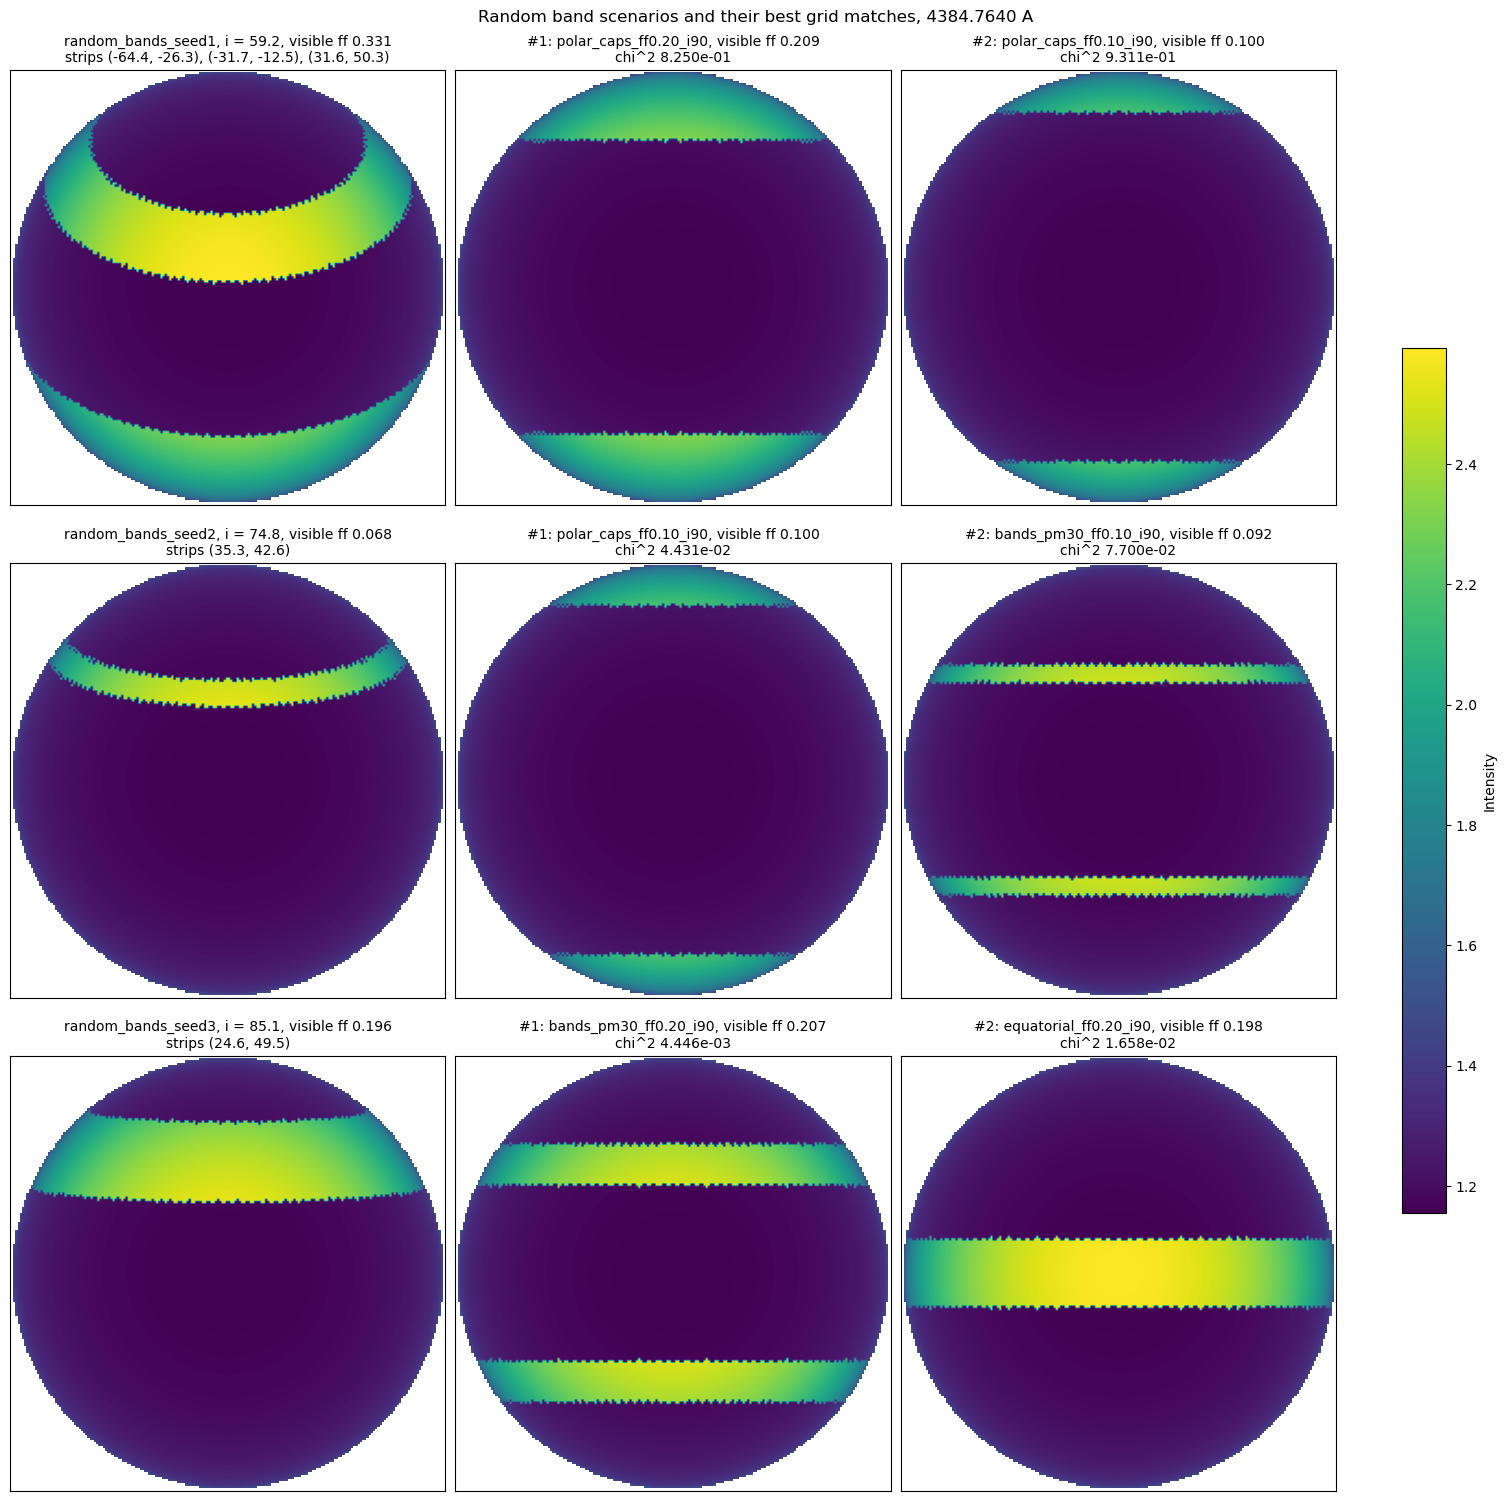

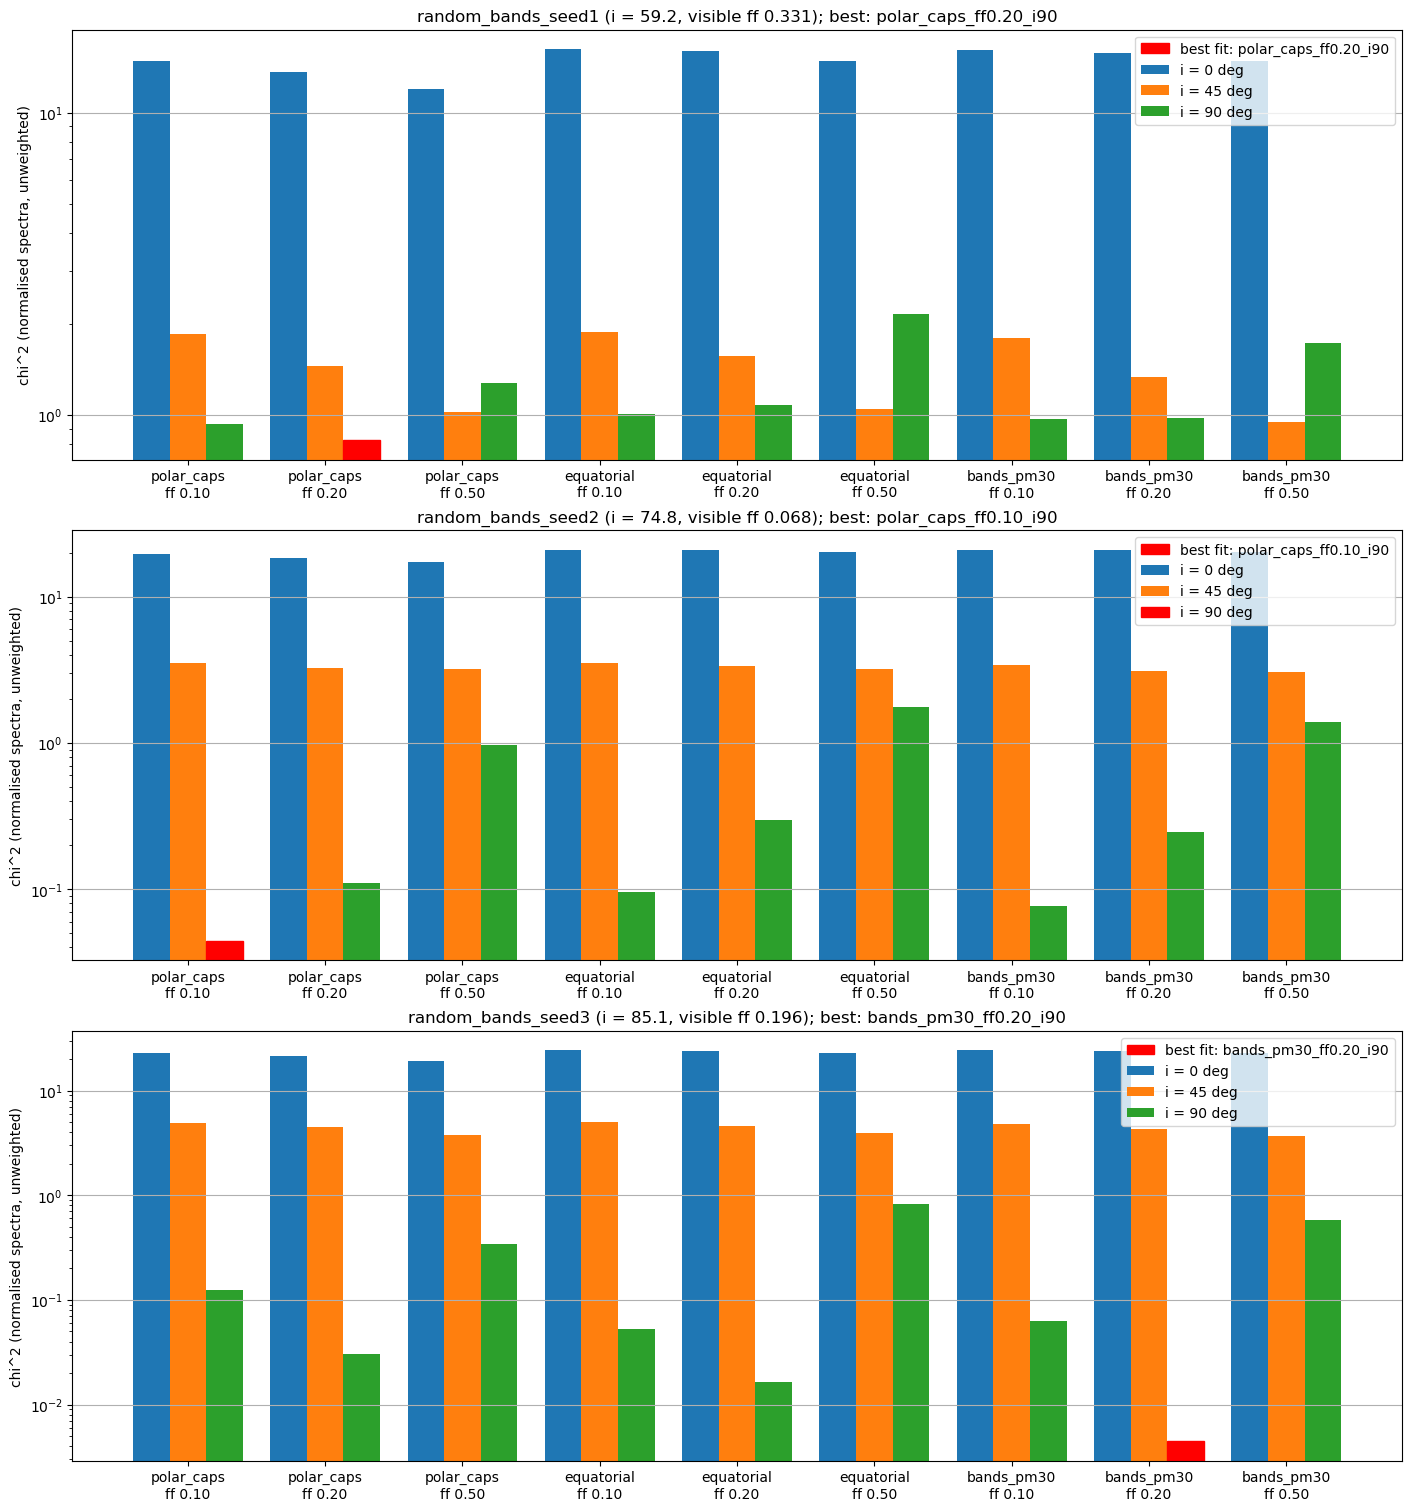

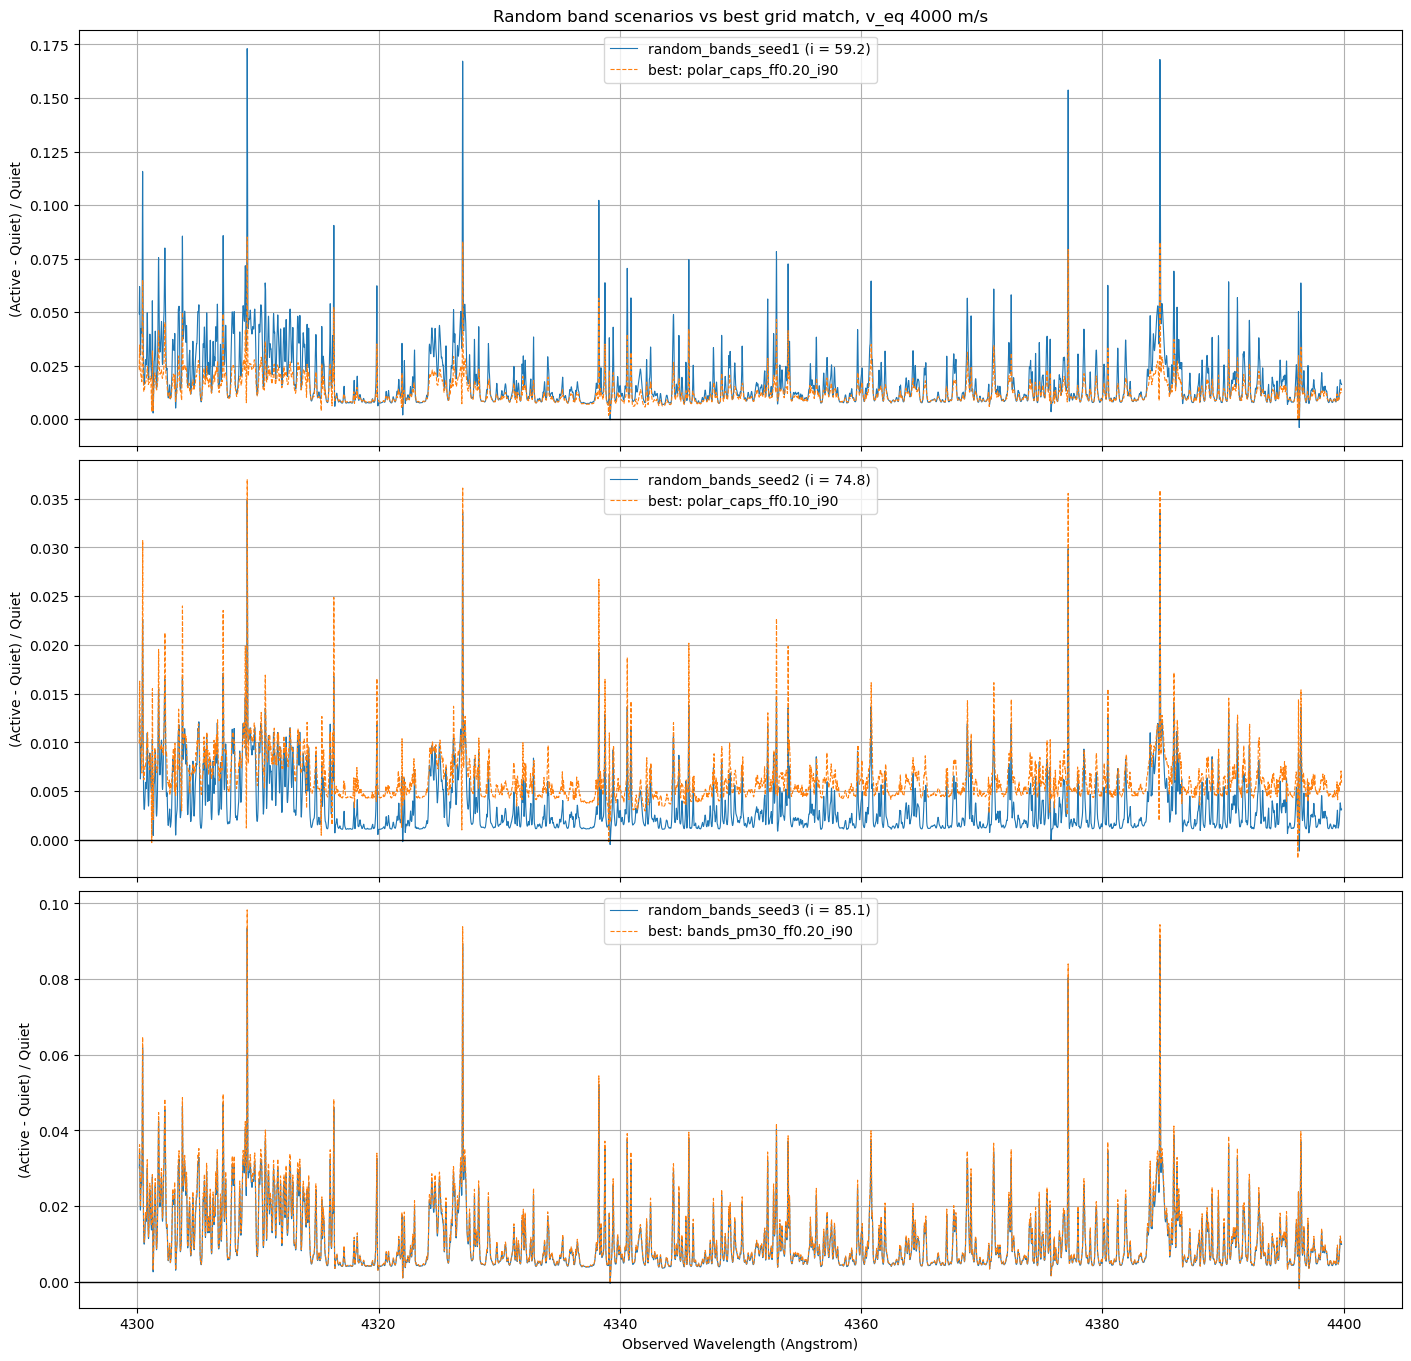

In [3]:
# ===== random facular band scenarios vs the grid =====
# Same chi^2 search as for the random faculae disk above, with targets made of randomly placed
# bands. Each scenario draws, from its own seed:
#   inclination       uniform in cos(i) over 0-90 deg (isotropic spin axes)
#   number of bands   uniform in {1, ..., band_n_max}
#   band centres      uniform in sin(lat) (uniform area), addstrip latitude convention
#                     (strip lat +90 is the pole facing us at i = 0)
#   band half-widths  uniform in band_half_width_range; NOT tuned, so the visible ff is whatever results
# A band with an edge beyond +/-90 is redrawn, because addstrip would reflect it silently.
# The grid only has i = 0, 45, 90, so inclination can be recovered only to that spacing.
# Uses the functions, grid spectra and common_bins from the cell above.
band_seeds = [1, 2, 3]
band_n_max = 3
band_half_width_range = (2.0, 20.0)   # deg

band_cache_file = (f'./outputs/gridsearch/1_gridsearch_randombands_v{grid_v_eq}_res3d{grid_res3d}_res2d{grid_res2d}'
                   f'_{grid_wav_lower * 1e10:.1f}_{grid_wav_higher * 1e10:.1f}'
                   f'_seeds{band_seeds[0]}-{band_seeds[-1]}.npz')


def draw_random_bands(seed):
    """(inc (deg), strips [(lower, upper)] deg, number of redrawn bands) for one scenario."""
    rng = np.random.default_rng(seed)
    inc = np.degrees(np.arccos(rng.uniform(0, 1)))
    n_bands = int(rng.integers(1, band_n_max + 1))
    strips = []
    n_redrawn = 0
    while len(strips) < n_bands:
        centre = np.degrees(np.arcsin(rng.uniform(-1, 1)))
        half_width = rng.uniform(*band_half_width_range)
        if centre - half_width < -90 or centre + half_width > 90:
            n_redrawn += 1
            continue
        strips.append((centre - half_width, centre + half_width))
    return inc, strips, n_redrawn


band_runs = []
for seed in band_seeds:
    inc, strips, n_redrawn = draw_random_bands(seed)
    ff = visible_fill(strips, [], inc)
    band_runs.append({'name': f'random_bands_seed{seed}', 'kind': 'random_bands', 'seed': seed, 'inc': inc,
                      'visible_ff': ff, 'strips': strips, 'faculae': [], 'n_redrawn': n_redrawn})
    # Its own quiet star, for the contrast plot: the grid only has quiet runs at 0, 45, 90.
    band_runs.append({'name': f'quiet_random_bands_seed{seed}', 'kind': 'quiet', 'seed': seed, 'inc': inc,
                      'visible_ff': 0.0, 'strips': [], 'faculae': [], 'n_redrawn': 0})

print(f"{'scenario':22s} {'i (deg)':>8s} {'visible ff':>10s} {'redrawn':>7s}  strips (lower, upper) deg")
for run in band_runs:
    if run['kind'] != 'random_bands':
        continue
    strips_text = ', '.join(f'({lower:.2f}, {upper:.2f})' for lower, upper in run['strips'])
    print(f"{run['name']:22s} {run['inc']:8.2f} {run['visible_ff']:10.4f} {run['n_redrawn']:7d}  {strips_text}")
    if run['visible_ff'] == 0:
        print(f"  WARNING: {run['name']} has no band on the visible disk; its target is the quiet star")

# ----- simulate, or load the cache -----
band_run_names = np.array([run['name'] for run in band_runs])
band_config = np.array([grid_v_eq, grid_res3d, grid_res2d, len(grid_input_wavelengths), band_n_max,
                        band_half_width_range[0], band_half_width_range[1]], dtype=float)
band_strip_edges = np.array([edge for run in band_runs for strip in run['strips'] for edge in strip] +
                            [run['inc'] for run in band_runs])
band_spectra = {}
if os.path.exists(band_cache_file):
    cached = np.load(band_cache_file)
    if not (np.array_equal(cached['run_names'], band_run_names) and np.array_equal(cached['config'], band_config)
            and np.array_equal(cached['strip_edges'], band_strip_edges)):
        raise ValueError(f"{band_cache_file} was made with different runs or settings. "
                         "Delete or rename it by hand if it should be replaced.")
    for name in band_run_names:
        band_spectra[name] = (cached[f'bins_{name}'], cached[f'spectrum_{name}'], cached[f'image_{name}'])
    print(f"\nLoaded {len(band_spectra)} spectra from {band_cache_file}")
else:
    t_start = time.time()
    ctx = mp.get_context('fork')
    with ctx.Pool(processes=min(grid_n_workers, len(band_runs))) as pool:
        results = pool.map(simulate_grid_spectrum, band_runs, chunksize=1)
    for run, result in zip(band_runs, results):
        band_spectra[run['name']] = result
    print(f"\nSimulated {len(band_runs)} runs x {len(grid_input_wavelengths)} wavelengths in {(time.time() - t_start) / 60:.1f} min")
    to_save = {'run_names': band_run_names, 'config': band_config, 'strip_edges': band_strip_edges,
               'incs': np.array([run['inc'] for run in band_runs]),
               'visible_ffs': np.array([run['visible_ff'] for run in band_runs])}
    for name, (bins, spectrum, image) in band_spectra.items():
        to_save[f'bins_{name}'] = bins
        to_save[f'spectrum_{name}'] = spectrum
        to_save[f'image_{name}'] = image
    np.savez(band_cache_file, **to_save)
    print(f"Wrote {band_cache_file}")

for name, (bins, spectrum, image) in band_spectra.items():
    if not np.all(np.isfinite(spectrum)) or np.any(spectrum <= 0):
        raise ValueError(f"{name}: non-finite or non-positive intensity in the spectrum")

# ----- chi^2 of each scenario against every grid spectrum -----
# Same statistic as above: spectra divided by their own mean over common_bins, unweighted.
def normalise_on_common_bins(bins, spectrum, label):
    on_common = np.isin(bins, common_bins)
    if on_common.sum() != len(common_bins):
        raise ValueError(f"{label} does not cover all {len(common_bins)} common bins")
    return spectrum[on_common] / np.mean(spectrum[on_common])

band_targets = [run for run in band_runs if run['kind'] == 'random_bands']
band_chi2 = {}
for target in band_targets:
    bins, spectrum, _ = band_spectra[target['name']]
    target_normalised = normalise_on_common_bins(bins, spectrum, target['name'])
    chi2_by_grid_name = {}
    for name in grid_names:
        chi2_by_grid_name[name] = np.sum((target_normalised - normalised_spectrum(name)) ** 2)
    band_chi2[target['name']] = chi2_by_grid_name

    ranked = sorted(chi2_by_grid_name, key=chi2_by_grid_name.get)
    target['ranked'] = ranked
    print(f"\n{target['name']}: i = {target['inc']:.2f} deg, visible ff {target['visible_ff']:.4f}, "
          f"{len(target['strips'])} band(s)")
    print(f"{'rank':>4s} {'run':28s} {'visible ff':>10s} {'chi^2':>12s}")
    for rank, name in enumerate(ranked[:5], start=1):
        print(f"{rank:4d} {name:28s} {runs_by_name[name]['visible_ff']:10.4f} {chi2_by_grid_name[name]:12.5e}")

# ----- images: each scenario next to its two best matches -----
def masked_band_image(name):
    image = band_spectra[name][2].copy()
    image[image == 0] = np.nan   # off-disk background
    return image

fig, axes = plt.subplots(len(band_targets), 3, figsize=(15, 5 * len(band_targets)), squeeze=False, constrained_layout=True)
for row, target in enumerate(band_targets):
    strips_text = ', '.join(f'({lower:.1f}, {upper:.1f})' for lower, upper in target['strips'])
    panels = [(masked_band_image(target['name']),
               f"{target['name']}, i = {target['inc']:.1f}, visible ff {target['visible_ff']:.3f}\nstrips {strips_text}")]
    for rank, name in enumerate(target['ranked'][:2], start=1):
        panels.append((masked_image(name), f"#{rank}: {name}, visible ff {runs_by_name[name]['visible_ff']:.3f}\n"
                                           f"chi^2 {band_chi2[target['name']][name]:.3e}"))
    for ax, (image, title) in zip(axes[row], panels):
        im = ax.imshow(image, cmap='viridis', vmin=image_vmin, vmax=image_vmax)
        ax.set_title(title, fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
fig.colorbar(im, ax=axes.ravel().tolist(), label='Intensity', shrink=0.6)
fig.suptitle(f'Random band scenarios and their best grid matches, {grid_input_wavelengths[grid_image_index]:.4f} A')
plt.show()

# ----- chi^2 across the grid, one panel per scenario -----
fig, axes = plt.subplots(len(band_targets), 1, figsize=(14, 5 * len(band_targets)), squeeze=False, constrained_layout=True)
for ax, target in zip(axes[:, 0], band_targets):
    for offset, inc in enumerate(grid_incs):
        chi2_values = [band_chi2[target['name']][f'{geometry}_ff{target_ff:.2f}_i{inc}']
                       for geometry, target_ff in scenario_columns]
        bars = ax.bar(x_positions + (offset - (len(grid_incs) - 1) / 2) * bar_width, chi2_values, width=bar_width, label=f'i = {inc} deg')
        # Lowest chi^2 over the whole grid: the numerical best fit
        for bar, (geometry, target_ff) in zip(bars, scenario_columns):
            if f'{geometry}_ff{target_ff:.2f}_i{inc}' == target['ranked'][0]:
                bar.set_color('red')
                bar.set_label(f"best fit: {target['ranked'][0]}")
    ax.set_xticks(x_positions)
    ax.set_xticklabels([f'{geometry}\nff {target_ff:.2f}' for geometry, target_ff in scenario_columns])
    ax.set_yscale('log')
    ax.set_ylabel('chi^2 (normalised spectra, unweighted)')
    ax.set_title(f"{target['name']} (i = {target['inc']:.1f}, visible ff {target['visible_ff']:.3f}); best: {target['ranked'][0]}")
    ax.legend()
    ax.grid(True, axis='y')
plt.show()

# ----- facular signal: contrast to each run's own quiet star -----
def band_contrast_to_quiet(target):
    bins, spectrum, _ = band_spectra[target['name']]
    quiet_bins, quiet_spectrum, _ = band_spectra[f"quiet_{target['name']}"]
    if not np.array_equal(bins, quiet_bins):
        raise ValueError(f"Bins of {target['name']} and its quiet run differ")
    on_common = np.isin(bins, common_bins)
    return (spectrum[on_common] - quiet_spectrum[on_common]) / quiet_spectrum[on_common]

fig, axes = plt.subplots(len(band_targets), 1, figsize=(14, 4.5 * len(band_targets)), sharex=True,
                         squeeze=False, constrained_layout=True)
for ax, target in zip(axes[:, 0], band_targets):
    ax.plot(common_bins, band_contrast_to_quiet(target), linewidth=0.8, label=f"{target['name']} (i = {target['inc']:.1f})")
    best = target['ranked'][0]
    ax.plot(common_bins, contrast_to_quiet(best), linewidth=0.8, linestyle='--', label=f'best: {best}')
    ax.axhline(0, color='k', linewidth=1)
    ax.set_ylabel('(Active - Quiet) / Quiet')
    ax.legend()
    ax.grid(True)
axes[-1, 0].set_xlabel('Observed Wavelength (Angstrom)')
axes[0, 0].set_title(f'Random band scenarios vs best grid match, v_eq {grid_v_eq} m/s')
plt.show()
